# Win or FF un proyecto semestral de ingeniería de datos

**Autores:** Lorenzo Lopez, Eloy Prado

## Descripción General
Este proyecto de Ingeniería de Datos busca desarrollar un modelo predictivo de clasificación binaria para determinar el equipo ganador en una partida competitiva de *League of Legends*, utilizando exclusivamente la información estadística disponible durante los primeros 10 minutos de juego.

## Planteamiento del Problema
En partidas competitivas de *League of Legends*, los jugadores y equipos suelen tomar decisiones estratégicas críticas durante el *early game* (juego temprano) basándose principalmente en la intuición o en percepciones subjetivas de ventaja (como iniciar una votación de rendición temprana o forzar peleas grupales en desventaja). 

Actualmente, existe la necesidad de identificar con precisión matemática qué ventajas concretas obtenidas en esta etapa temprana definen realmente el resultado final de la partida. La falta de claridad sobre el peso real de acciones específicas (como el control de visión versus la ventaja de oro o la captura de objetivos neutrales) dificulta la optimización en la toma de decisiones para maximizar la probabilidad de victoria.

# Importación de Librerías

Lo primero será importar las librerías utilizadas para la creación del modelo que solucionará nuestro problema.

In [11]:
#Para crear los dataframes de entrenamiento y testeo
import pandas as pd
from sklearn.model_selection import train_test_split

#Para entrenar el modelo y exportarlo como un archivo
from sklearn.ensemble import RandomForestClassifier
import joblib

#Para testear el modelo
from sklearn.metrics import accuracy_score, precision_score, recall_score

#Variables importantes
nombre_archivo = 'modelo_ff_rf.pkl'

#Para crear graficos
import matplotlib

ModuleNotFoundError: No module named 'matplotlib'

# Preparación de los Datos

Acto seguido sería tomar el dataset de entrada y a partir de él crear dos dataframes, uno de entrenamiento y otro de testeo. Estos serán en una proporción de 80% de los datos en el dataframe de entrenamiento y el 20% restante en el dataframe de testeo.

In [ ]:
df = pd.read_csv('../Script/high_diamond_ranked_10min/high_diamond_ranked_10min.csv')

#el 80% de las filas deberán de estar en el dataset de entrenamiento mientras el 20% restante será usado para el testeo
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df['blueWins'])

# Entrenamiento de modelo

Ahora para entrenar el modelo, vamos a trabajar con random forest. Se observa en este caso en la línea donde de inicializa el RandomForestClassifier que su constructor tiene 2 parámetros, **n_estimators** y **random_state**. Estos lo que nos indican es que:
* **n_estimators:** Esto indica que tendremos 100 árboles de decisión que promedian sus predicciones para reducir el sobreajuste.

* **random_state:** Indica la semilla para que el modelo siempre tenga el mismo punto de origen y así si perdemos el modelo que utilizamos hoy mañana podamos crear exactamente el mismo asumiendo que preservamos el set de entrenamiento.

In [ ]:
X_train = df_train.drop(columns=['blueWins', 'gameId'])
y_train = df_train['blueWins']

modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)

modelo_rf.fit(X_train, y_train)

nombre_archivo = 'modelo_ff_rf.pkl'
joblib.dump(modelo_rf, nombre_archivo)

print(f"Listo el modelo fue guardado como '{nombre_archivo}'")

Listo el modelo fue guardado como 'modelo_ff_rf.pkl'


# Testeo de Modelo

Este paso es esencial para verificar que el modelo creado efectivamente es útil y determinar su precisión, recall y accuracy.

En la primera línea hacemos que la variable X_test ignore en el dataframe de entrenamiento las columnas **blueWins** que es nuestra variable objetivo y **gameId** que no aporta información útil para la predicción sino únicamente ruido ya que solo es el identificador de la partida mas no tiene nada que ver con cómo los jugadores se desempeñaron en ella.

In [ ]:
X_test = df_test.drop(columns=['blueWins', 'gameId'])
y_test = df_test['blueWins']

predicciones = modelo_rf.predict(X_test)

accuracy = accuracy_score(y_test, predicciones)
precision = precision_score(y_test, predicciones)
recall = recall_score(y_test,predicciones)

print(f"Accuracy o exactitud: {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")

Accuracy o exactitud: 71.71%
Precision: 72.17%
Recall: 70.49%


# Identificación de Variables Importantes

Ahora que tenemos un modelo, debemos de determinar a qué variables le está dando más importancia el modelo. Para esto crearemos un nuevo data frame con la información de cada variable y su importancia para el modelo.

10 variables más importantes:


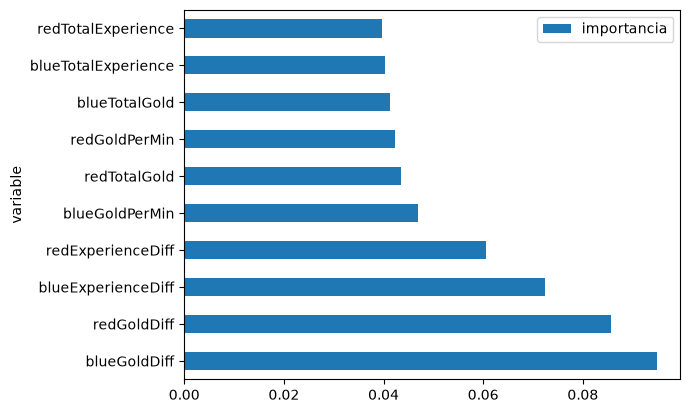

In [17]:
importancias = modelo_rf.feature_importances_
nombres_variables = X_train.columns

df_importancias = pd.DataFrame({
    'variable': nombres_variables,
    'importancia': importancias 
})

df_importancias = df_importancias.sort_values(by='importancia', ascending=False)

print("10 variables más importantes:")

df_importancias.head(10).plot(kind='barh', x='variable', y='importancia');

Los resultados indican que las variables más determinantes son las ventajas netas de recursos: diferencia de oro (blueGoldDiff, redGoldDiff) y diferencia de experiencia (blueExperienceDiff, redExperienceDiff). Es importante notar que el dataset utilizado presenta características espejo (multicolinealidad), por lo que la ventaja de oro para el equipo azul es la desventaja de oro para el equipo rojo lo que el modelo logra identificar.